# Python versus C: multiplying matrices

Notebook 01 compared Python and C on a simple loop. Now we compare them on the operation that matters for AI: matrix multiplication with the three nested loops from notebook 02. The algorithm is exactly the same in both languages, so any difference in speed comes from *how each language runs it*.

Speed is measured in **GFLOPS**: billions of floating-point operations per second, counting $2n^3$ operations for two $n \times n$ matrices (notebook 02). Higher is better, and unlike seconds, GFLOPS can be compared between matrix sizes.

## Matrix multiplication in pure Python

Matrices are lists of lists of numbers. The function is stored in the project's own small package, `compare_efficiency`, so that other notebooks can reuse it:

In [ ]:
import inspect

from compare_efficiency.matmul_pure_python import matmul_pure_python

print(inspect.getsource(matmul_pure_python))

def matmul_pure_python(matrix_a: Matrix, matrix_b: Matrix) -> Matrix:
    n = len(matrix_a)
    result = [[0.0] * n for _ in range(n)]
    for i in range(n):
        for j in range(n):
            total = 0.0
            for k in range(n):
                total += matrix_a[i][k] * matrix_b[k][j]
            result[i][j] = total
    return result



Before timing anything, we check that the result is correct by comparing it with NumPy. Decimal numbers are always slightly rounded, so they are compared with a small tolerance using `np.allclose`, never with `==`. A fast wrong answer would be worthless.

In [ ]:
import numpy as np

from compare_efficiency.benchmark import random_matrices

matrix_a, matrix_b = random_matrices(64)
reference_result = matrix_a @ matrix_b

python_result = matmul_pure_python(matrix_a.tolist(), matrix_b.tolist())
np.allclose(python_result, reference_result)

True

`time_function` runs the function once without timing it (a **warm-up**, so one-off costs are not counted), then several more times, and returns the **median** time, the middle value, so that one run disturbed by something else on the computer does not distort the result.

The sizes stop at 256: the work grows as $n^3$, so every doubling of $n$ costs eight times more time.

In [ ]:
from compare_efficiency.benchmark import gflops, time_function

python_seconds = {}
for n in [64, 128, 256]:
    list_a, list_b = (matrix.tolist() for matrix in random_matrices(n))
    python_seconds[n] = time_function(lambda: matmul_pure_python(list_a, list_b), repeats=3)

{n: f"{seconds * 1000:.0f} ms, {gflops(n, seconds):.2f} GFLOPS" for n, seconds in python_seconds.items()}

{64: '8 ms, 0.07 GFLOPS',
 128: '38 ms, 0.11 GFLOPS',
 256: '315 ms, 0.11 GFLOPS'}

## The same algorithm in C

The file `c/matmul.c` contains the same algorithm in C, written in two versions:

- `matmul_ijk` has exactly the same three loops as the Python function.
- `matmul_ikj` performs exactly the same multiplications and additions, but with the two inner loops swapped. We will see in a moment why that matters.

In [ ]:
from compare_efficiency.project_paths import C_DIRECTORY

print((C_DIRECTORY / "matmul.c").read_text())

// Naive square matrix multiplication C = A @ B, for n x n matrices stored row-major in flat arrays.
// Both functions perform exactly 2 * n^3 floating-point operations; they differ only in loop order.

#include <stddef.h>

// Textbook order: the innermost loop walks B down a column, jumping n doubles in memory at every step.
void matmul_ijk(const double *a, const double *b, double *c, size_t n) {
    for (size_t i = 0; i < n; i++) {
        for (size_t j = 0; j < n; j++) {
            double sum = 0.0;
            for (size_t k = 0; k < n; k++) {
                sum += a[i * n + k] * b[k * n + j];
            }
            c[i * n + j] = sum;
        }
    }
}

// Swapped order: the innermost loop walks rows of B and C contiguously, so every cache line is fully used
// and the compiler can vectorise it with SIMD instructions.
void matmul_ikj(const double *a, const double *b, double *c, size_t n) {
    for (size_t i = 0; i < n * n; i++) {
        c[i] = 0.0;
    }
    for (size_t i = 0

This time the C code is not compiled into a program of its own. It is compiled into a **shared library**: a file of compiled functions that other programs can load and call. Python loads it with `ctypes`, a standard module for calling C functions, and passes it the NumPy matrices. `compile_c_library` runs `gcc` with the strongest optimisation (`-O3`), and asks it to use every instruction this particular processor supports (`-march=native`).

Keep this idea in mind, a Python program calling compiled C functions from a library file, because it is the key to notebook 04.

In [ ]:
from compare_efficiency.c_library import call_c_matmul, compile_c_library, load_c_library

c_library = load_c_library(compile_c_library(["-O3", "-march=native"], "O3"))
c_versions = {"C, same loops (ijk)": c_library.matmul_ijk, "C, swapped loops (ikj)": c_library.matmul_ikj}

{name: np.allclose(call_c_matmul(function, matrix_a, matrix_b), reference_result) for name, function in c_versions.items()}

{'C, same loops (ijk)': True, 'C, swapped loops (ikj)': True}

In [ ]:
c_seconds = {}
for n in [256, 1024]:
    matrix_a_n, matrix_b_n = random_matrices(n)
    c_seconds[n] = {name: time_function(lambda: call_c_matmul(function, matrix_a_n, matrix_b_n), repeats=3)
                    for name, function in c_versions.items()}

{n: {name: f"{seconds * 1000:.1f} ms, {gflops(n, seconds):.1f} GFLOPS" for name, seconds in by_version.items()}
 for n, by_version in c_seconds.items()}

{256: {'C, same loops (ijk)': '13.7 ms, 2.5 GFLOPS',
  'C, swapped loops (ikj)': '1.0 ms, 35.2 GFLOPS'},
 1024: {'C, same loops (ijk)': '4074.2 ms, 0.5 GFLOPS',
  'C, swapped loops (ikj)': '59.0 ms, 36.4 GFLOPS'}}

## Comparing the results

All three versions at $n = 256$, the largest size that pure Python ran. The horizontal axis is **logarithmic**: each gridline is ten times faster than the previous one.

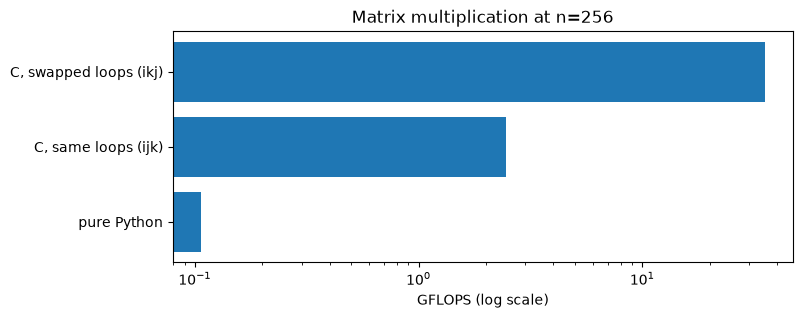

In [ ]:
import matplotlib.pyplot as plt

comparison_size = 256
speed_in_gflops = {"pure Python": gflops(comparison_size, python_seconds[comparison_size])}
speed_in_gflops |= {name: gflops(comparison_size, seconds) for name, seconds in c_seconds[comparison_size].items()}

figure, axis = plt.subplots(figsize=(8, 3))
axis.barh(list(speed_in_gflops), list(speed_in_gflops.values()))
axis.set_xscale("log")
axis.set_xlabel("GFLOPS (log scale)")
axis.set_title(f"Matrix multiplication at n={comparison_size}")
plt.show()

In [ ]:
{name: f"{speed / speed_in_gflops['pure Python']:.0f}x faster than pure Python"
 for name, speed in speed_in_gflops.items() if name != "pure Python"}

{'C, same loops (ijk)': '23x faster than pure Python',
 'C, swapped loops (ikj)': '330x faster than pure Python'}

With exactly the same loops, C is already many times faster than Python. With the loops reordered, the gap grows to **several hundred times**.

Why does the order of the loops matter so much, if the arithmetic is identical? Because of **memory**. C stores a matrix row by row, like the lines of a book. The swapped version reads the numbers along each row, in order, like reading a book line by line. The original version, in its innermost loop, walks down a column, like reading only the first word of every line: each step jumps far away in memory. Processors are very fast at reading memory in order and much slower at jumping around, so the same arithmetic can run many times faster.

→ Deep dive: [Loop order and the cache](deep-dives/loop_order_and_cache.ipynb) explains this with the processor's cache and measures it across sizes.

## Why Python is so much slower

The causes add up:

- **The interpreter.** Python translates and carries out the innermost line again at every step, $n^3$ times, as in notebook 01. The C code was translated once, in advance.
- **Checking types at every step.** Before each `*` and `+`, Python checks what kind of values it has, because they could be integers, decimals or even text. In C the types were fixed and checked before the program ran.
- **Numbers wrapped in objects.** Every Python number is a small object with extra information attached, reached through its memory address, and every multiplication creates a new object for its result. C works on the bare numbers.
- **No hardware tricks.** Modern processors can apply one instruction to several numbers at once. The C compiler can use those instructions for a simple loop; the Python interpreter, handling one number object at a time, cannot.

→ Deep dives: [How programs run](deep-dives/how_programs_run.ipynb) and [Numbers and memory](deep-dives/numbers_and_memory.ipynb) look at each of these causes in detail.

## Key ideas

- The same matrix multiplication runs **hundreds of times faster in C** than in pure Python.
- Python is slower because it interprets every step, checks types at every operation and wraps every number in an object.
- Even in C, the **order in which memory is read** changes the speed enormously.
- C code can be compiled into a **shared library** and called from Python. That will turn out to be the answer to the puzzle.